# Ảnh hưởng của phân phối biến nhiễu đến chất lượng ước lượng ATE

In [68]:
import os, sys
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from typing import Tuple

from distribution import Simulation, SCENARIOS
from balance import check_balance, summarize, iptw_weights, trim_summary, overlap_mask, effective_sample_size
from methods import estimate_all

# Tham số cố dịnh 
SEED=251
N=2000
PS_ESTIMATED=True
# --- Giao diện biểu đồ: nền sáng, nét mảnh, lưới nhạt ---
BLUE, RED, ORANGE, GREEN, INK = "#3fa6e1", "#e04444", "#d26f28", "#7ED386", "#0b0b0b"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "axes.titlesize": 10, "axes.titleweight": "regular",
    "axes.titlelocation": "center", "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

Simulation.list_scenarios()

,id,name,description
0,1,baseline,"X1~N(0;1), X2~N(0;1)"
1,2,weak_overlap,"X1~N(0;1), X2~N(0;9)"
2,3,outlier,"X1~N(0;1), X2~t(df=2)"
3,4,skewed,"X1~N(0;1), X2~Exp(1)-1"
4,5,bimodal,"X1~N(0;1), X2~Bimodal"
5,6,skewed_outlier,"X1~Exp(1)-1, X2~t(df=2)"
6,7,skewed_bimodal,"X1~Exp(1)-1, X2~Bimodal"
7,8,outlier_bimodal,"X1~t(df=2), X2~Bimodal"


`inspect_case(name)` cho một kịch bản: phân phối của X1, X2 và e(X) theo nhóm, bảng balance trước/sau IPTW, và ATE ước lượng của 4 phương pháp (một lần chạy).
Tham số hay dùng: `n`, `seed`, `use_estimated_ps` (tự ước lượng e(X) thay vì dùng e thật), và hai tham số xử lý overlap:

- `trim` (ví dụ 0.05) cùng `trim_mode="drop"` (mặc định): **trimming**, loại các quan sát có e(X) ngoài [trim, 1-trim], ước lượng trên phần còn lại.
- `trim_mode="clip"`: **clipping**, giữ mọi quan sát nhưng ép e(X) về [trim, 1-trim] (để so sánh, thường gây chệch).

In [3]:
def love_plot(table, ax=None, title="Covariate balance trước và sau gán trọng số",
              threshold=0.1, abs_smd=False, sort=True):
    """Love plot từ bảng của check_balance. Truyền ax để vẽ nhiều kịch bản trên một lưới."""
    t = table.copy()
    if sort:
        t = t.reindex(t["smd_before"].abs().sort_values(ascending=False).index)
    before, after = t["smd_before"].to_numpy(), t["smd_after"].to_numpy()
    if abs_smd:
        before, after = np.abs(before), np.abs(after)
    k = len(t)
    ypos = np.arange(k)

    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(6.5, max(2.2, 0.45 * k + 1.3)))
    for s in ((threshold,) if abs_smd else (-threshold, threshold)):
        ax.axvline(s, color=RED, lw=1, ls="--")
    ax.axvline(0, color=RED, lw=0.8, alpha=0.6, zorder=2)
    ax.scatter(before, ypos, color=GREEN, s=45, zorder=3, label="Trước weighting")
    ax.scatter(after, ypos, color=BLUE, s=45, zorder=3, label="Sau IPTW")
    ax.set_yticks(ypos)
    ax.set_yticklabels(t.index)
    ax.set_ylim(k - 0.5, -0.5)
    ax.set_xlabel("|Standardized difference|" if abs_smd else "Standardized difference")
    ax.set_title(title, loc="center")
    ax.grid(axis="y", alpha=0)
    ax.legend(title="", frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
    if own:
        fig.tight_layout(rect=[0, 0, 0.85, 1])
        plt.show()
    else:
        return ax

In [4]:
def _kde(x, grid, bw_adjust=1.0):
    """KDE Gauss tính bằng numpy (không cần scipy). Băng thông Silverman dùng thước đo bền
    min(std, IQR/1.34) nên không bị phình ra khi đuôi dày như t(df=2)."""
    x = np.asarray(x, dtype=float)
    q75, q25 = np.percentile(x, [75, 25])
    scale = min(x.std(ddof=1), (q75 - q25) / 1.34)
    h = bw_adjust * 0.9 * scale * len(x) ** (-1 / 5)
    dens = np.zeros_like(grid)
    for i in range(0, len(grid), 200):                      
        z = (grid[i:i + 200, None] - x[None, :]) / h
        dens[i:i + 200] = np.exp(-0.5 * z ** 2).sum(axis=1)
    return dens / (len(x) * h * np.sqrt(2 * np.pi))


def _hist(ax, x, color, title, bins=60, label=None, alpha=0.55,
          kde=True, bw_adjust=1.0, line_color="#eb2828"):
    x = np.asarray(x, dtype=float)
    lo, hi = np.percentile(x, [0.5, 99.5])
    edges = np.linspace(lo, hi, bins)
    width = edges[1] - edges[0]
    ax.hist(x, bins=edges, weights=np.full(len(x), 1 / (len(x) * width)), color=color, alpha=alpha,
            label=label, histtype="stepfilled", edgecolor=color, linewidth=1.0)
    if kde:
        grid = np.linspace(lo, hi, 300)
        ax.plot(grid, _kde(x, grid, bw_adjust), color=line_color, lw=1)
    ax.set_xlim(lo, hi)
    ax.set_title(title)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)


def inspect_case(name, n=N, seed=SEED, trim=None, trim_mode="drop", use_estimated_ps=PS_ESTIMATED):
    # sinh dữ liệu mô phỏng theo kịch bản
    sim = Simulation(name, n=n, seed=seed)
    df = sim.generate()
    print(f"Kịch bản: {name}  |  {sim.description}  |  n={n}, gamma0={sim.gamma0:.2f}, ATE thật={sim.ate}")
    display(Simulation.summary(df).round(3).to_frame("giá trị").T)
    # vẽ đồ thị 
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.0))
    _hist(axes[0], df["X1"].to_numpy(), GREEN, "Phân phối của X1")
    _hist(axes[1], df["X2"].to_numpy(), GREEN, "Phân phối của X2")
    for a_val, color, lab in [(1, BLUE, "A=1 (treated)"), (0, RED, "A=0 (control)")]:
        axes[2].hist(df.loc[df.A == a_val, "e"], bins=np.linspace(0, 1, 41), color=color, alpha=0.55,
                     histtype="stepfilled", edgecolor=color, linewidth=1.0, label=lab)
    axes[2].set_title("Propensity score e(X) theo nhóm")
    axes[2].set_yticks([])
    axes[2].legend(frameon=False, loc="upper right")
    fig.tight_layout()
    plt.show()
    # số lượng cắt dữ liệu 
    label = "" if trim is None else f" (trim={trim}, {trim_mode})"
    if trim is not None:
        print("Số quan sát ngoài vùng overlap" + label)
        display(trim_summary(df, trim, trim_mode=trim_mode).to_frame("giá trị").T)
    
    # kiểm tra cân bằng 
    print("Balance trước / sau gán trọng số IPTW" + (f" (trim={trim})" if trim else ""))
    tbl = check_balance(df, trim=trim, trim_mode=trim_mode)
    display(tbl.round(3))
    love_plot(tbl, title=name)
    print("Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW")
    display(effective_sample_size(df, trim=trim, trim_mode=trim_mode).round(3))

    # tính ước lượng
    est = estimate_all(df, use_estimated_ps=use_estimated_ps, trim=trim, trim_mode=trim_mode)
    keep = overlap_mask(df["e"], trim) if (trim is not None and trim_mode == "drop") else np.ones(len(df), bool)
    truth = df.loc[keep, "tau"].mean()
    print(f"ATE ước lượng (thật = {sim.ate})")
    display(pd.DataFrame({"ATE_hat": est, "bias": est - sim.ate}).round(3).T)
    return df

## Từng kịch bản

### 1. baseline

$X_1, X_2 \sim N(0;1)$. Mốc so sánh: kỳ vọng OLS, IPTW, AIPW gần ATE thật; chỉ naive chệch (do nhiễu).

Kịch bản: baseline  |  X1~N(0;1), X2~N(0;1)  |  n=2000, gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.488,0.088,0.938,0.0,9.651,0.867


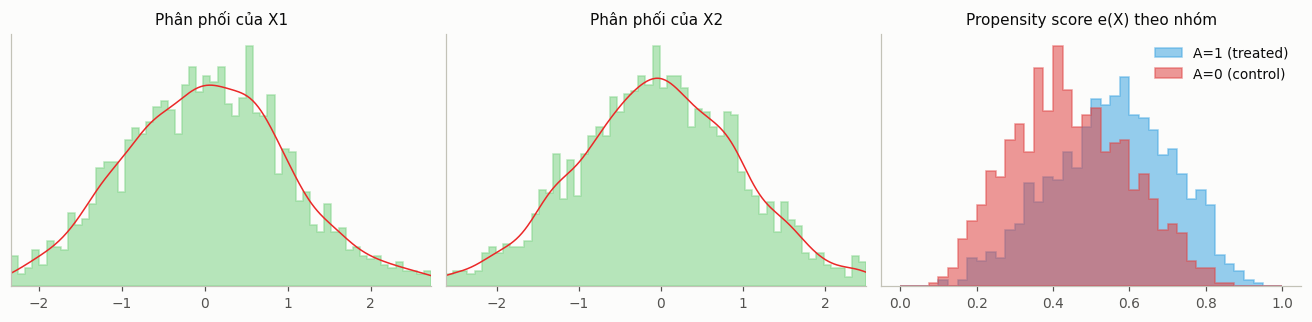

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.534,1.155,False,0.051,1.149,True
X2,0.452,1.084,False,-0.037,1.129,True


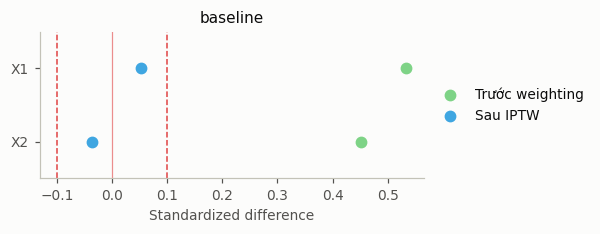

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1734.264,0.867
treated (A=1),977,977,834.721,0.854
control (A=0),1023,1023,900.303,0.880


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,2.522,2.027,2.027,2.034
bias,0.522,0.027,0.027,0.034


In [29]:
df1 = inspect_case("baseline", n=N, seed=SEED)

### 2. weak_overlap

$X_1 \sim N(0;1),\ X_2 \sim N(0;9)$. Phương sai lớn làm $e(X)$ dồn về 0/1, IPTW có trọng số cực đoan.

Kịch bản: weak_overlap  |  X1~N(0;1), X2~N(0;9)  |  n=2000, gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.484,0.008,0.993,0.003,35.791,0.459


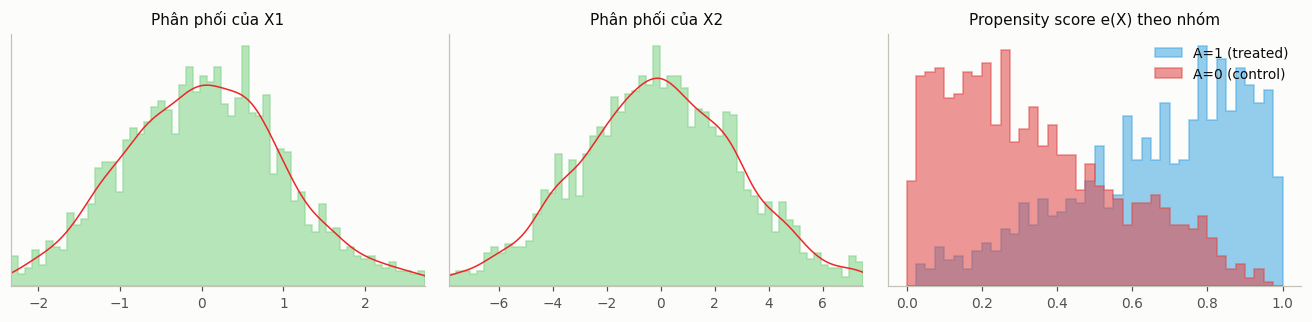

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.376,1.017,False,-0.045,0.992,True
X2,1.269,1.057,False,0.028,1.311,True


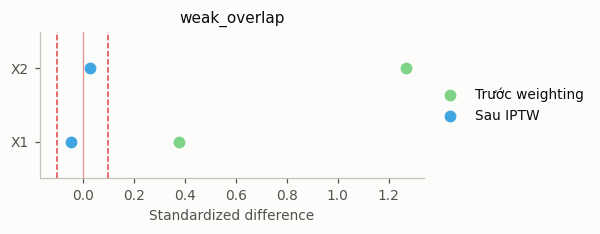

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,917.273,0.459
treated (A=1),967,967,373.854,0.387
control (A=0),1033,1033,603.564,0.584


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,3.835,2.005,1.921,2.001
bias,1.835,0.005,-0.079,0.001


In [30]:
df2 = inspect_case("weak_overlap", n=N, seed=SEED)

### 3. outlier

$X_2 \sim t(df=2)$. Đuôi dày, phương sai vô hạn: vài điểm cực đoan chi phối IPTW và có leverage lớn trong OLS.

Kịch bản: outlier  |  X1~N(0;1), X2~t(df=2)  |  n=2000, gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.507,0.0,1.0,0.014,18.4,0.751


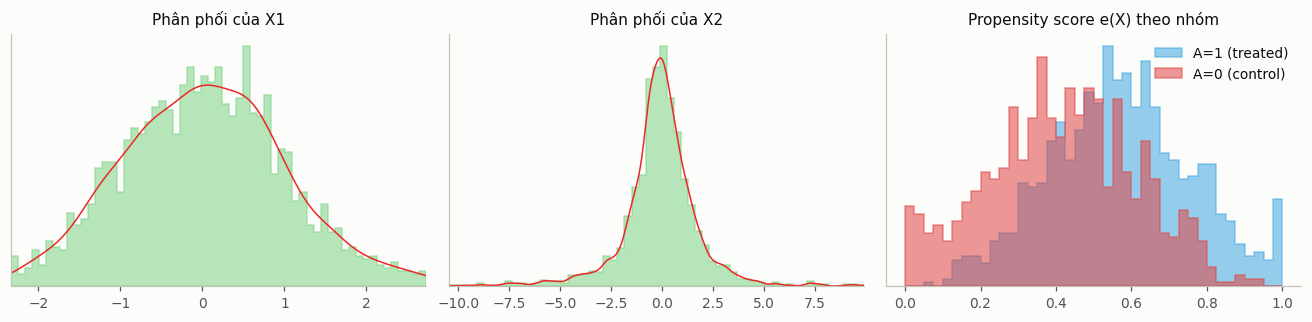

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.385,1.025,False,-0.060,0.958,True
X2,0.569,1.026,False,0.056,0.971,True


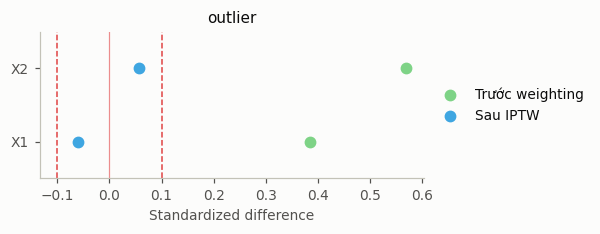

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1502.579,0.751
treated (A=1),1015,1015,781.286,0.770
control (A=0),985,985,721.784,0.733


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,2.982,1.988,2.169,1.999
bias,0.982,-0.012,0.169,-0.001


In [31]:
df3 = inspect_case("outlier", n=N, seed=SEED)

### 4. skewed

$X_2 \sim Exp(1)-1$. Lệch phải, đuôi nhẹ hơn $t$; thiếu overlap cục bộ ở đuôi phải.

Kịch bản: skewed  |  X1~N(0;1), X2~Exp(1)-1  |  n=2000, gamma0=0.01, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.505,0.102,0.974,0.0,10.953,0.883


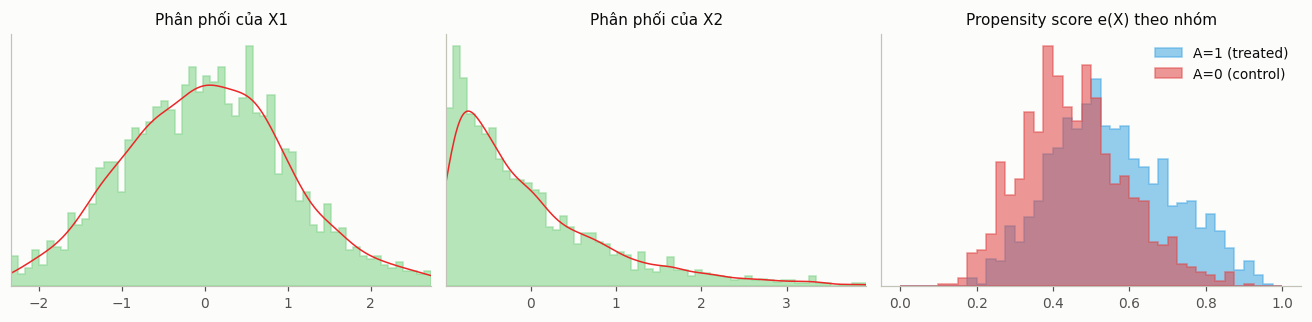

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.489,1.031,False,0.034,0.966,True
X2,0.437,2.234,False,0.038,1.157,True


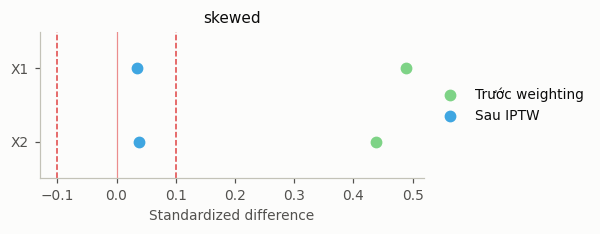

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1766.369,0.883
treated (A=1),1010,1010,914.019,0.905
control (A=0),990,990,854.097,0.863


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,2.429,1.953,1.948,1.942
bias,0.429,-0.047,-0.052,-0.058


In [32]:
df4 = inspect_case("skewed", n=N, seed=SEED)

### 5. bimodal

$X_2$ hai đỉnh tại $\pm 0.8$ (phương sai 1). Kỳ vọng ít khác baseline vì mô hình tham số vẫn đúng.

Kịch bản: bimodal  |  X1~N(0;1), X2~Bimodal  |  n=2000, gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.496,0.113,0.901,0.0,7.969,0.875


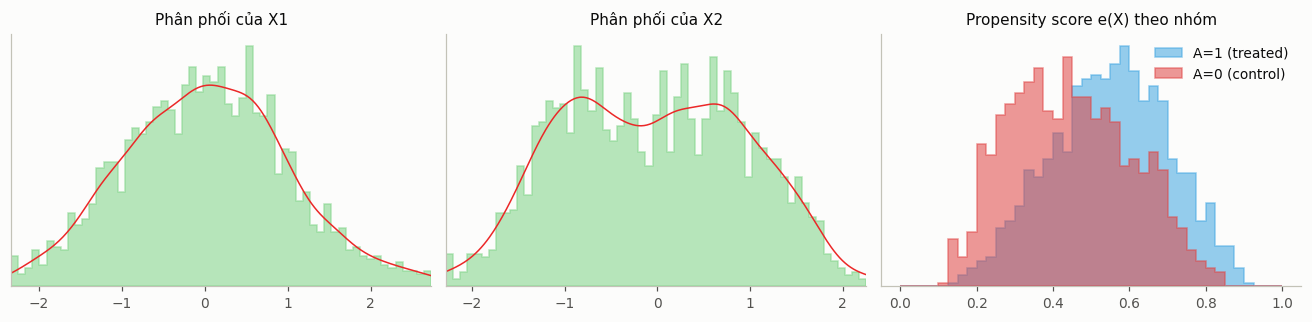

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.435,1.054,False,-0.035,1.025,True
X2,0.500,0.937,False,0.014,0.923,True


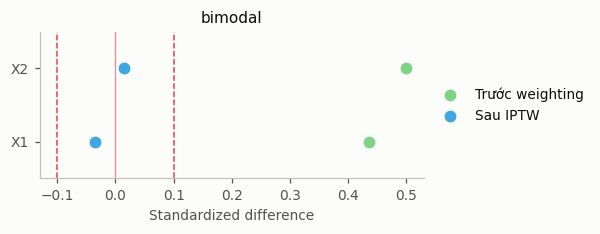

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1750.145,0.875
treated (A=1),992,992,870.107,0.877
control (A=0),1008,1008,880.043,0.873


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,2.486,2.015,2.022,2.014
bias,0.486,0.015,0.022,0.014


In [33]:
df5 = inspect_case("bimodal", n=N, seed=SEED)

### 6. skewed + outlier

$X_1 \sim Exp(1)-1,\ X_2 \sim t(df=2)$. Độ lệch kết hợp đuôi dày.

Kịch bản: skewed_outlier  |  X1~Exp(1)-1, X2~t(df=2)  |  n=2000, gamma0=0.01, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.486,0.0,1.0,0.012,58.305,0.548


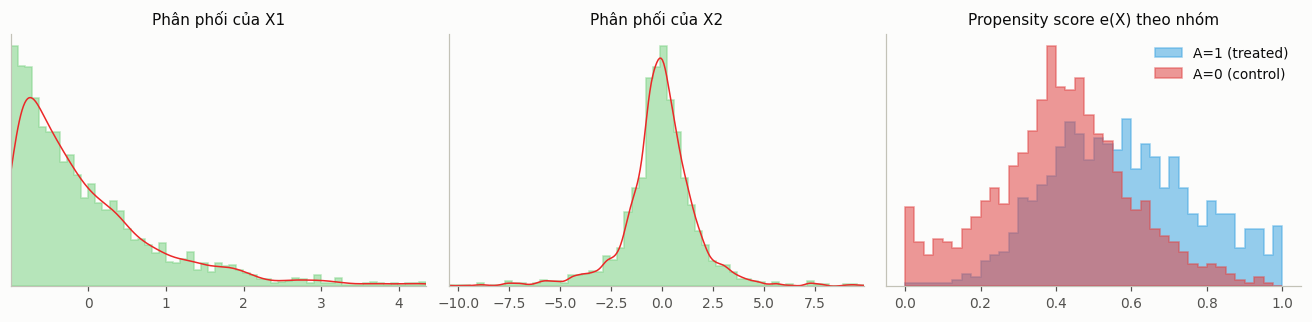

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.430,2.424,False,0.021,1.010,True
X2,0.575,1.131,False,-0.046,1.207,True


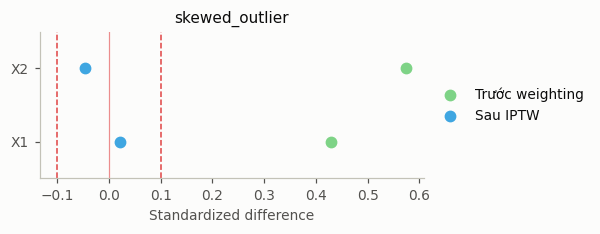

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1095.572,0.548
treated (A=1),972,972,468.707,0.482
control (A=0),1028,1028,653.933,0.636


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,3.038,2.048,2.108,2.07
bias,1.038,0.048,0.108,0.07


In [34]:
df6 = inspect_case("skewed_outlier", n=N, seed=SEED)

### 7. skewed + bimodal

$X_1 \sim Exp(1)-1,\ X_2$ bimodal.

Kịch bản: skewed_bimodal  |  X1~Exp(1)-1, X2~Bimodal  |  n=2000, gamma0=0.01, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.498,0.14,0.989,0.0,13.114,0.884


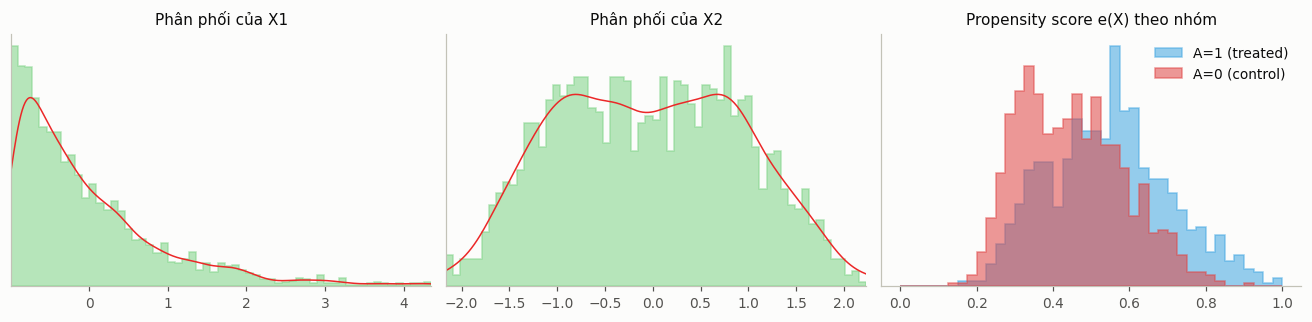

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.482,2.450,False,0.079,1.163,True
X2,0.399,1.017,False,-0.059,1.021,True


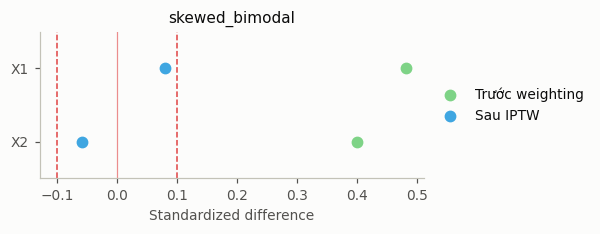

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1768.464,0.884
treated (A=1),997,997,891.857,0.895
control (A=0),1003,1003,876.607,0.874


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,2.441,2.003,2.008,1.999
bias,0.441,0.003,0.008,-0.001


In [35]:
df7 = inspect_case("skewed_bimodal", n=N, seed=SEED)

### 8. outlier + bimodal

$X_1 \sim t(df=2),\ X_2$ bimodal.

Kịch bản: outlier_bimodal  |  X1~t(df=2), X2~Bimodal  |  n=2000, gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.486,0.0,1.0,0.011,41.383,0.669


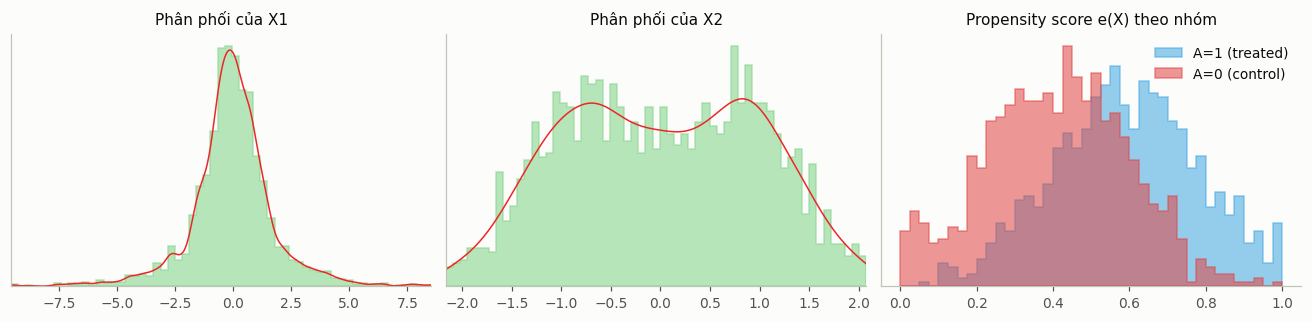

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.668,1.039,False,0.095,0.906,True
X2,0.451,0.975,False,-0.014,0.962,True


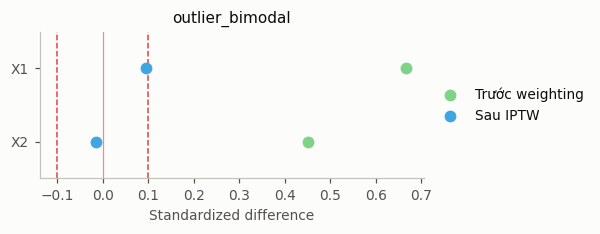

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1338.149,0.669
treated (A=1),972,972,749.856,0.771
control (A=0),1028,1028,611.825,0.595


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,3.072,2.062,2.132,2.127
bias,1.072,0.062,0.132,0.127


In [36]:
df8 = inspect_case("outlier_bimodal", n=N, seed=SEED)

In [ ]:
import pandas as pd

SCES = ["baseline","weak_overlap","outlier","skewed","bimodal","skewed_outlier","skewed_bimodal","outlier_bimodal"]
df = [df1, df2, df3, df4, df5, df6, df7, df8]

summaries = {s: Simulation.summary(i) for s, i in zip(SCES, df)}

data = pd.DataFrame({
        "scenario": SCES,
        "ess_ratio": [summaries[s]["ess_ratio"] for s in SCES],
        "e_outside": [summaries[s]["e_outside"] for s in SCES]
})


In [77]:
data

,scenario,ess_ratio,e_outside
0,baseline,0.867132,0.0000
1,weak_overlap,0.458637,0.0030
2,outlier,0.751290,0.0135
3,skewed,0.883185,0.0000
4,bimodal,0.875073,0.0000
5,skewed_outlier,0.547786,0.0115
6,skewed_bimodal,0.884232,0.0000
7,outlier_bimodal,0.669075,0.0110


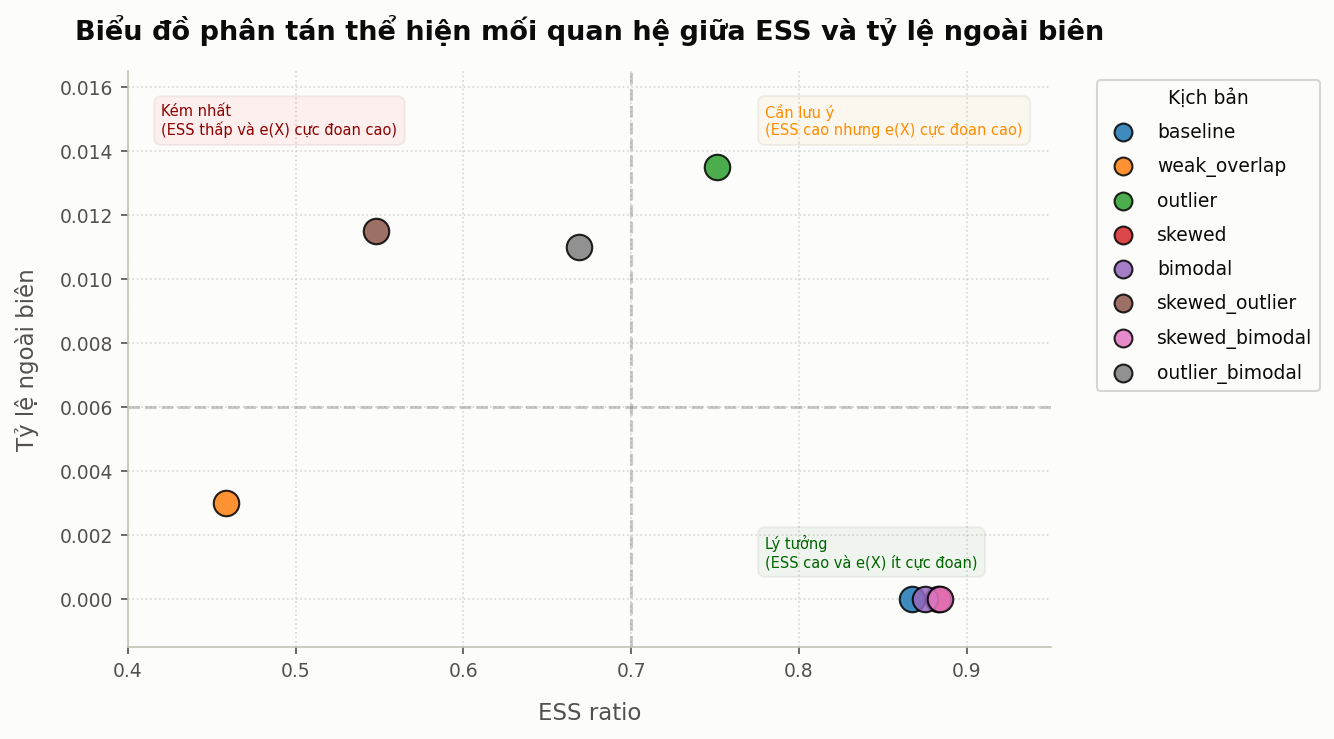

In [106]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Đặt màu sắc riêng biệt cho từng kịch bản
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']

plt.figure(figsize=(9, 5), dpi=150)
# Trực quan các điểm
for idx, row in data.iterrows():
    plt.scatter(row['ess_ratio'], row['e_outside'], color=colors[idx], s=150, edgecolors='black', label = row["scenario"], alpha=0.85)

# Phân vùng (quadrants)
plt.axvline(x=0.7, color='gray', linestyle='--', alpha=0.4)
plt.axhline(y=0.006, color='gray', linestyle='--', alpha=0.4)

plt.text(0.42, 0.0145, "Kém nhất\n(ESS thấp và e(X) cực đoan cao)", fontsize=7, color='darkred', bbox=dict(facecolor='red', alpha=0.05, boxstyle='round,pad=0.5'))
plt.text(0.78, 0.0145, "Cần lưu ý\n(ESS cao nhưng e(X) cực đoan cao)", fontsize=7, color='darkorange', bbox=dict(facecolor='orange', alpha=0.05, boxstyle='round,pad=0.5'))
plt.text(0.78, 0.001, "Lý tưởng\n(ESS cao và e(X) ít cực đoan)", fontsize=7, color='darkgreen', bbox=dict(facecolor='green', alpha=0.05, boxstyle='round,pad=0.5'))

plt.xlabel("ESS ratio", fontsize=11, labelpad=10)
plt.ylabel("Tỷ lệ ngoài biên", fontsize=11, labelpad=10)
plt.title("Biểu đồ phân tán thể hiện mối quan hệ giữa ESS và tỷ lệ ngoài biên", fontsize=13, fontweight='bold', pad=15)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(title="Kịch bản", bbox_to_anchor=(1.04, 1), labelspacing=0.8, markerscale=0.7, loc="upper left")
plt.xlim(0.4, 0.95)
plt.ylim(-0.0015, 0.0165)
plt.tight_layout()
plt.show()

## Trimming và clipping: cách nào cứu được IPTW?

Hai cách xử lý quan sát có e(X) cực đoan khác nhau về bản chất:

- **Trimming** (`trim_mode="drop"`, mặc định): loại quan sát có e(X) ngoài [trim, 1-trim]. Quan sát còn lại giữ trọng số 1/e đúng, nên IPTW vẫn không chệch, nhưng estimand đổi thành ATE **trên vùng overlap**. Cả 4 phương pháp dùng cùng mẫu đã trim.
- **Clipping** (`trim_mode="clip"`): giữ mọi quan sát nhưng ép e(X) về [trim, 1-trim]. Trọng số không còn là 1/e thật nên bị chệch.

`compare_trim` chạy một kịch bản với nhiều ngưỡng. `n_kept` là số quan sát còn lại, `ess_ratio` là ESS chia cho n ban đầu (nên trimming bị phản ánh đúng mức mất mẫu).
Trong mô phỏng này $\tau(X)=\tau_0$ không đổi, nên ATE trên vùng overlap vẫn bằng ATE thật. 

In [ ]:
def compare_trim(name, trims=(None, 0.01, 0.05, 0.1), n=N, seed=SEED, use_estimated_ps=PS_ESTIMATED, trim_mode="drop"):
    sim = Simulation(name, n=n, seed=seed)
    df = sim.generate()
    rows = {}
    tau = sim.ate
    i = 0 
    for t in trims:
        est = estimate_all(df, use_estimated_ps=use_estimated_ps, trim=t, trim_mode=trim_mode)
        s = summarize(check_balance(df, trim=t, trim_mode=trim_mode))
        ess = effective_sample_size(df, trim=t, trim_mode=trim_mode).loc["toàn mẫu"]
        rows[i] = {"mode": "không trim" if t is None else f"trim={t}", 
            "n_kept": int(ess["n_kept"]), "ess_ratio": ess["ess_ratio"],
            "bias_iptw_abs": np.abs(est["iptw"]-tau), "bias_aipw_abs": np.abs(est["aipw"]-tau), "bias_ols_abs": np.abs(est["ols"]-tau),
            "max_|SMD|_sau": s["max_abs_smd_after"], "can_bang_sau": s["all_balanced_after"],
        }
        i+=1
    print(f"{name} | trim_mode={trim_mode} | ATE thật = {sim.ate}")
    return pd.DataFrame(rows).T
WEAK = ["weak_overlap", "outlier", "skewed_outlier", "outlier_bimodal"]
for w in WEAK:
    display(compare_trim(w, trim_mode="drop").round(3))
    display(compare_trim(w, trim_mode="clip").round(3))

weak_overlap | trim_mode=drop | ATE thật = 2.0


,mode,n_kept,ess_ratio,bias_iptw_abs,bias_aipw_abs,bias_ols_abs,max_|SMD|_sau,can_bang_sau
0,không trim,2000,0.458637,0.078675,0.000949,0.005195,0.045154,True
1,trim=0.01,1994,0.457406,0.099666,0.003414,0.0048,0.049738,True
2,trim=0.05,1852,0.555585,0.02899,0.005757,0.002193,0.06167,True
3,trim=0.1,1646,0.604908,0.060476,0.047109,0.020377,0.086313,True


weak_overlap | trim_mode=clip | ATE thật = 2.0


,mode,n_kept,ess_ratio,bias_iptw_abs,bias_aipw_abs,bias_ols_abs,max_|SMD|_sau,can_bang_sau
0,không trim,2000,0.458637,0.078675,0.000949,0.005195,0.045154,True
1,trim=0.01,2000,0.458638,0.078633,0.00095,0.005195,0.045145,True
2,trim=0.05,2000,0.528513,0.045792,0.008452,0.005195,0.093324,True
3,trim=0.1,2000,0.640751,0.261035,0.02324,0.005195,0.234008,False


outlier | trim_mode=drop | ATE thật = 2.0


,mode,n_kept,ess_ratio,bias_iptw_abs,bias_aipw_abs,bias_ols_abs,max_|SMD|_sau,can_bang_sau
0,không trim,2000,0.75129,0.169066,0.001414,0.012404,0.060485,True
1,trim=0.01,1973,0.743125,0.068222,0.004014,0.01706,0.062626,True
2,trim=0.05,1930,0.729909,0.003387,0.001882,0.014162,0.081051,True
3,trim=0.1,1878,0.773826,0.009891,0.013993,0.01842,0.075156,True


... (6 outputs left out)

outlier_bimodal | trim_mode=drop | ATE thật = 2.0


,mode,n_kept,ess_ratio,bias_iptw_abs,bias_aipw_abs,bias_ols_abs,max_|SMD|_sau,can_bang_sau
0,không trim,2000,0.669075,0.131889,0.127403,0.062338,0.094531,True
1,trim=0.01,1978,0.662878,0.035392,0.123934,0.076389,0.022469,True
2,trim=0.05,1944,0.750377,0.068686,0.107421,0.084296,0.033007,True
3,trim=0.1,1888,0.779204,0.110822,0.10467,0.087434,0.02771,True


outlier_bimodal | trim_mode=clip | ATE thật = 2.0


,mode,n_kept,ess_ratio,bias_iptw_abs,bias_aipw_abs,bias_ols_abs,max_|SMD|_sau,can_bang_sau
0,không trim,2000,0.669075,0.131889,0.127403,0.062338,0.094531,True
1,trim=0.01,2000,0.66911,0.132691,0.127424,0.062338,0.095125,True
2,trim=0.05,2000,0.746237,0.182208,0.105024,0.062338,0.128511,False
3,trim=0.1,2000,0.795148,0.263969,0.116053,0.062338,0.166736,False


In [120]:
# Danh sách chứa tất cả các dòng dữ liệu cần trích xuất
records = []

for w in WEAK:
    df_none = compare_trim(w, trims=(None,), trim_mode="drop")
    df_trim = compare_trim(w, trims=(0.05,), trim_mode="drop")
    df_clip = compare_trim(w, trims=(0.05,), trim_mode="clip")
    # Thêm dữ liệu baseline
    row_none = df_none.iloc[0].to_dict()
    row_none["scenario"] = w
    row_none["method"] = "None"
    records.append(row_none)
    # Thêm dữ liệu trimming với trim=0.05
    row_trim = df_trim.iloc[0].to_dict()
    row_trim["scenario"] = w
    row_trim["method"] = "Trimming"
    records.append(row_trim)
    # Thêm dữ liệu clipping với trim =0.05
    row_clip = df_clip.iloc[0].to_dict()
    row_clip["scenario"] = w
    row_clip["method"] = "Clipping"
    records.append(row_clip)

# 4. Gom tất cả thành 1 DataFrame duy nhất
data_compare_trim = pd.DataFrame(records)

# Đổi tên/sắp xếp lại các cột cho gọn gàng
data_compare_trim = data_compare_trim[["scenario", "method", "n_kept", "ess_ratio", "bias_iptw_abs", "bias_aipw_abs", "bias_ols_abs",
                                        "max_|SMD|_sau", "can_bang_sau"]]
display(data_compare_trim.round(4))

weak_overlap | trim_mode=drop | ATE thật = 2.0
weak_overlap | trim_mode=drop | ATE thật = 2.0
weak_overlap | trim_mode=clip | ATE thật = 2.0
outlier | trim_mode=drop | ATE thật = 2.0
outlier | trim_mode=drop | ATE thật = 2.0
outlier | trim_mode=clip | ATE thật = 2.0
skewed_outlier | trim_mode=drop | ATE thật = 2.0
skewed_outlier | trim_mode=drop | ATE thật = 2.0
skewed_outlier | trim_mode=clip | ATE thật = 2.0
outlier_bimodal | trim_mode=drop | ATE thật = 2.0
outlier_bimodal | trim_mode=drop | ATE thật = 2.0
outlier_bimodal | trim_mode=clip | ATE thật = 2.0


,scenario,method,n_kept,ess_ratio,bias_iptw_abs,bias_aipw_abs,bias_ols_abs,max_|SMD|_sau,can_bang_sau
0,weak_overlap,None,2000,0.4586,0.0787,0.0009,0.0052,0.0452,True
1,weak_overlap,Trimming,1852,0.5556,0.0290,0.0058,0.0022,0.0617,True
2,weak_overlap,Clipping,2000,0.5285,0.0458,0.0085,0.0052,0.0933,True
3,outlier,None,2000,0.7513,0.1691,0.0014,0.0124,0.0605,True
4,outlier,Trimming,1930,0.7299,0.0034,0.0019,0.0142,0.0811,True
5,outlier,Clipping,2000,0.7518,0.1760,0.0013,0.0124,0.0619,True
6,skewed_outlier,None,2000,0.5478,0.1075,0.0697,0.0478,0.0455,True
7,skewed_outlier,Trimming,1929,0.7474,0.0401,0.0489,0.0519,0.0307,True
8,skewed_outlier,Clipping,2000,0.7092,0.1525,0.0589,0.0478,0.0329,True
9,outlier_bimodal,None,2000,0.6691,0.1319,0.1274,0.0623,0.0945,True


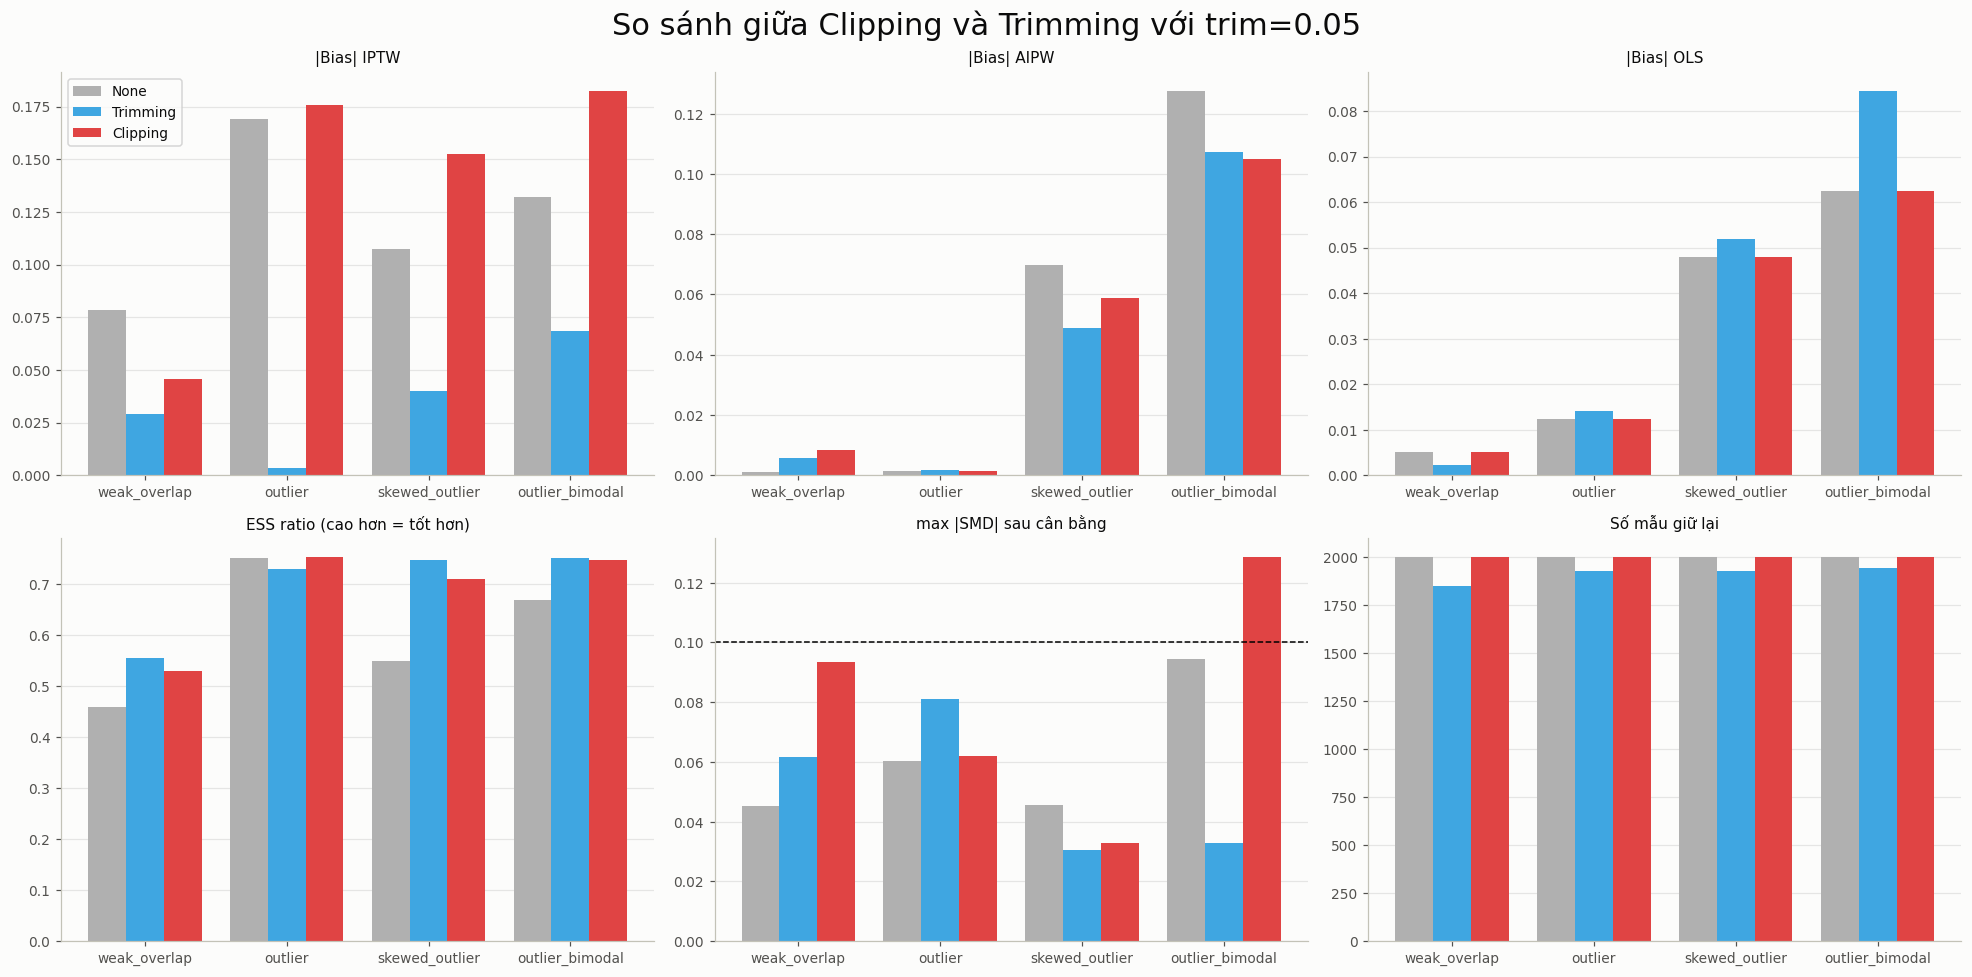

In [136]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_compare_trim(df, trim=0.05, include_none=True, figsize=(18, 9)):
    """
    So sánh Clipping vs Trimming (và baseline None) trên các scenario.
    df: DataFrame data_compare_trim.
    """
    metrics = [
        ("bias_iptw_abs", "|Bias| IPTW"),
        ("bias_aipw_abs", "|Bias| AIPW"),
        ("bias_ols_abs", "|Bias| OLS"),
        ("ess_ratio", "ESS ratio (cao hơn = tốt hơn)"),
        ("max_|SMD|_sau", "max |SMD| sau cân bằng"),
        ("n_kept", "Số mẫu giữ lại"),
    ]
    methods = ["None", "Trimming", "Clipping"] if include_none else ["Trimming", "Clipping"]
    colors = {"None": "#b0b0b0", "Trimming": BLUE, "Clipping": RED}

    d = df.copy()
    d["method"] = d["method"].astype(str)          
    scenarios = list(d["scenario"].unique())
    x = np.arange(len(scenarios))
    w = 0.8 / len(methods)

    fig, axes = plt.subplots(2, 3, figsize=figsize)
    for ax, (col, title) in zip(axes.ravel(), metrics):
        for i, m in enumerate(methods):
            sub = d[d["method"] == m].set_index("scenario").reindex(scenarios)
            ax.bar(x + (i - (len(methods) - 1) / 2) * w, sub[col], w,
                   label=m, color=colors[m])
        ax.set_title(title)
        ax.set_xticks(x)
        ax.set_xticklabels(scenarios, ha="center")
        ax.grid(axis="y", alpha=0.3)
    # ngưỡng SMD 0.1
    axes[1, 1].axhline(0.1, color="k", ls="--", lw=1)
    axes[0, 0].legend()
    fig.suptitle(f"So sánh giữa Clipping và Trimming với trim=0.05", fontsize=20)
    plt.tight_layout()
    plt.show()


def summarize_compare_trim(df):
    """Bảng so sánh Trimming - Clipping theo từng scenario (âm = Trimming tốt hơn với các cột bias/SMD)."""
    d = df.copy()
    d["method"] = d["method"].astype(str)
    cols = ["bias_iptw_abs", "bias_aipw_abs", "bias_ols_abs", "ess_ratio", "max_|SMD|_sau"]
    t = d[d["method"] == "Trimming"].set_index("scenario")[cols]
    c = d[d["method"] == "Clipping"].set_index("scenario")[cols]
    diff = (t - c).add_suffix("_diff")

    # điểm: đếm số scenario mà mỗi phương pháp thắng ở từng chỉ số
    wins = pd.DataFrame({
        "Trimming thắng": [(t[k] < c[k]).sum() if k != "ess_ratio" else (t[k] > c[k]).sum() for k in cols],
        "Clipping thắng": [(c[k] < t[k]).sum() if k != "ess_ratio" else (c[k] > t[k]).sum() for k in cols],
    }, index=cols)
    return diff.round(4), wins


# --- chạy ---
plot_compare_trim(data_compare_trim, trim=0.05)
diff, wins = summarize_compare_trim(data_compare_trim)

In [137]:
display(diff)
display(wins)

,bias_iptw_abs_diff,bias_aipw_abs_diff,bias_ols_abs_diff,ess_ratio_diff,max_|SMD|_sau_diff
scenario,,,,,
weak_overlap,-0.0168,-0.0027,-0.0030,0.0271,-0.0317
outlier,-0.1726,0.0006,0.0018,-0.0219,0.0192
skewed_outlier,-0.1124,-0.0100,0.0040,0.0382,-0.0022
outlier_bimodal,-0.1135,0.0024,0.0220,0.0041,-0.0955


,Trimming thắng,Clipping thắng
bias_iptw_abs,4,0
bias_aipw_abs,2,2
bias_ols_abs,1,3
ess_ratio,3,1
max_|SMD|_sau,3,1


## So sánh cả 8 kịch bản bằng mô phỏng lặp

Một lần chạy dễ gây nhiễu, nên `monte_carlo` lặp `reps` lần rồi trả về **bias** và **RMSE** của từng phương pháp.

In [ ]:
METHODS = ["naive", "ols", "iptw", "aipw"]

def monte_carlo(name, n=N, reps=1000, trim=None, use_estimated_ps=PS_ESTIMATED, seed=SEED):
    sim = Simulation(name, n=n, seed=seed)
    est = pd.DataFrame([estimate_all(sim.generate(), use_estimated_ps=use_estimated_ps, trim=trim)
                        for _ in range(reps)])
    return pd.DataFrame({
        "bias": est.mean() - sim.ate,
        "rmse": np.sqrt(((est - sim.ate) ** 2).mean()),
    })

def mc_all(**kw):
    res = {k: monte_carlo(k, **kw) for k in SCENARIOS}
    bias = pd.DataFrame({k: v["bias"] for k, v in res.items()}).T[METHODS]
    rmse = pd.DataFrame({k: v["rmse"] for k, v in res.items()}).T[METHODS]
    return bias, rmse

bias, rmse = mc_all(n=N, reps=200)
print("Bias"); display(bias.round(3))
print("RMSE"); display(rmse.round(3))

Bias


,naive,ols,iptw,aipw
baseline,0.449,-0.003,-0.002,-0.002
weak_overlap,1.725,-0.003,-0.002,-0.003
outlier,0.993,-0.003,0.065,-0.002
skewed,0.432,-0.007,-0.007,-0.007
bimodal,0.454,-0.002,-0.001,-0.002
skewed_outlier,0.985,0.005,0.060,0.008
skewed_bimodal,0.437,0.001,0.002,0.000
outlier_bimodal,0.999,-0.002,0.093,-0.001


RMSE


,naive,ols,iptw,aipw
baseline,0.452,0.045,0.048,0.047
weak_overlap,1.726,0.052,0.163,0.068
outlier,1.002,0.044,0.320,0.057
skewed,0.436,0.049,0.054,0.049
bimodal,0.457,0.044,0.045,0.045
skewed_outlier,0.988,0.049,0.252,0.084
skewed_bimodal,0.440,0.043,0.053,0.044
outlier_bimodal,1.005,0.046,0.157,0.059


In [ ]:
from matplotlib.colors import LinearSegmentedColormap, LogNorm

METHOD_COLORS = {"ols": BLUE, "iptw": RED, "aipw": GREEN}


def plot_mc(bias, rmse, methods=("ols", "iptw", "aipw"), title=None):
    """
    Ba ô cùng hàng kịch bản: Bias | Độ lệch chuẩn | RMSE  (RMSE^2 = Bias^2 + SD^2).
    bias, rmse: DataFrame (index = kịch bản, cột = phương pháp), như kết quả của mc_all().
    naive mặc định bị bỏ vì quá lớn làm các phương pháp còn lại dính sát nhau.
    """
    sd = np.sqrt(np.clip(rmse ** 2 - bias ** 2, 0, None))
    panels = [("Bias (độ chệch)", bias), ("SD (độ biến động)", sd), ("RMSE (sai số tổng)", rmse)]
    names = list(bias.index)
    y = np.arange(len(names))

    fig, axes = plt.subplots(1, 3, figsize=(12, 0.42 * len(names) + 1.6), sharey=True)
    for ax, (ttl, tab) in zip(axes, panels):
        for yi in y:                                              # đường dẫn mắt theo hàng
            ax.axhline(yi, color="#e1e0d9", lw=0.6, zorder=1)
        for m in methods:
            ax.scatter(tab[m], y, s=48, color=METHOD_COLORS[m], label=m, zorder=3,
                       edgecolor="#fcfcfb", linewidth=1.2)        # viền nền tách các điểm chồng nhau
        if ttl.startswith("Bias"):
            ax.axvline(0, color=INK, lw=1, zorder=2)
        ax.set_title(ttl)
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(y); axes[0].set_yticklabels(names); axes[0].set_ylim(len(names) - 0.5, -0.5)
    axes[2].legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    fig.tight_layout(rect=[0, 0.04, 1, 1])
    plt.show()


def heatmap_mc(tab, title="RMSE theo kịch bản và phương pháp", fmt="{:.3f}"):
    """Bản đồ nhiệt có ghi số cho toàn bộ bảng (gồm cả naive). Thang màu log để thấy cả 0.04 lẫn 1.7."""
    cmap = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
    vals = tab.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(0.95 * tab.shape[1] + 2.2, 0.42 * tab.shape[0] + 1.2))
    norm = LogNorm(vmin=vals[vals > 0].min(), vmax=vals.max())
    ax.imshow(vals, cmap=cmap, norm=norm, aspect="auto")
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            ax.text(j, i, fmt.format(vals[i, j]), ha="center", va="center", fontsize=9,
                    color="white" if norm(vals[i, j]) > 0.55 else INK)
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(tab.index)
    ax.xaxis.tick_top(); ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.grid(False)
    ax.set_title(title, loc="center", pad=28)
    fig.tight_layout(); plt.show()

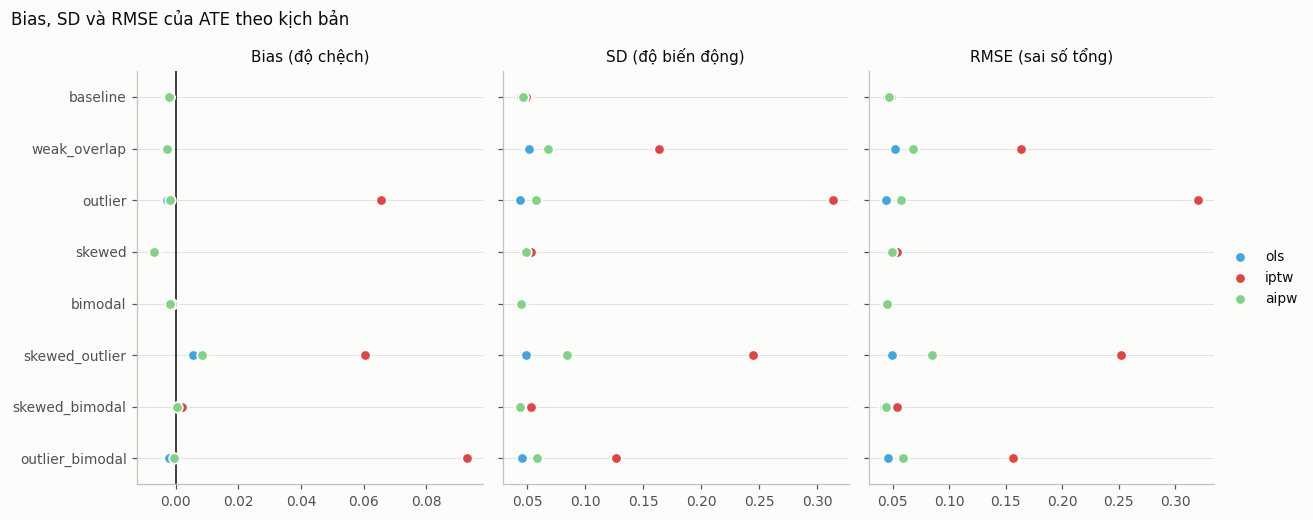

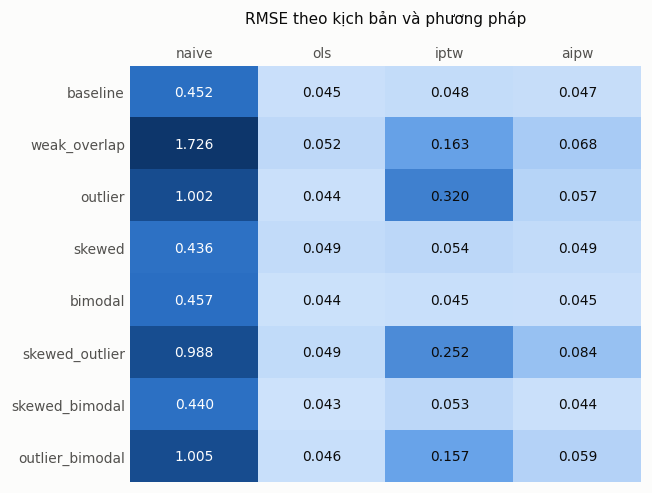

In [17]:
plot_mc(bias, rmse, title="Bias, SD và RMSE của ATE theo kịch bản")
heatmap_mc(rmse)

# Kết luận 
Phân phối của biến nhiễu X không ảnh hưởng đến hiệu quả ước lượng và độ chệch, tuy nhiên, việc phân phối có outlier hoặc đuôi dày khiến cho e(X) có các giá trị cực đoan => cần các phương pháp xử lý outlier và các giá trị cực đoan của e(X) 

# Đề xuất hướng làm tiếp theo
- Các phương pháp xử lý outlier của phân phối, liệu outlier của phân phối có xử lý tương tự outlier thực tế hay không? (bản thân phân phối có outlier chứ không phải outlier tự thêm)?
- Các phương pháp xử lý giá trị cực đoan của e(X) => liệu có phương pháp ước lượng nào xử lý được các giá trị cực đoan mà không cần đến việc cut giá trị cực đoan của e(X) hay không?